temp:
- `/gpfs/radev/home/yl2426/project/SocialLearning/EPhys_data_2026-04/2026-09-08_PLV_analy`

**Rhythmic synchronization**: two signals from diff. sources have phase-relationship in a particular frequency band
- strength & precision of this rhythmic synchronization is indicative of bias between 

**Glossary**

| term | meaning | Link | 
|---|---|---|
| PLV | "Phase-locking Value" mean resultant length of a unit's spike phases. aalso referred to as mean vector length (MVL). Assumes unimodal/von mises distribution.| [Lachaux et al., 1999](https://www.sciencedirect.com/science/article/pii/S1053811910000959#bib13) |
| PPC | pairwise phase consistency: measuring average angular distance (cosine of difference) btwn. all spike pairs independent of trial or spike counts.| [Vinck et al. 2010](https://www.sciencedirect.com/science/article/pii/S1053811910000959) |
| Rayleigh Test | Classical hypothesis test of circular uniformity: whether computed phases are non-uniform around circle or in preferred direction (unimodal distribution) | [Berens 2009, *CircStat*](https://www.jstatsoft.org/article/view/v031i10) |


**See also**:
- [MgM's Analysis of Electrophysiological Data in Neuroscience](https://mgm248.github.io/ephys_data_analysis_book/2_ST_LFP_Spike_LFP_Coupling.html#mean-vector-length)

package requirements:
- python==3.12.2
- ipykernel==6.29.3

- numpy==1.26.0
- scipy==1.15.1
- matplotlib==3.10.0
- pandas==2.2.3


In [46]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, hilbert
from scipy import signal as sig
from scipy.special import i0, i1
import math
import itertools
import random
import time

from pathlib import Path
import pandas as pd

In [ ]:
## Constants

LFP_SAMPLING_RATE = 1000
IIR_ORDER = 4
BAND = [12, 32]  # Hz, beta band around the simulated 20 Hz rhythm
RAYLEIGH_ALPHA = 0.05

# Directory path. Change to user directory.
PROJECT_DIR = Path("/project_dir")




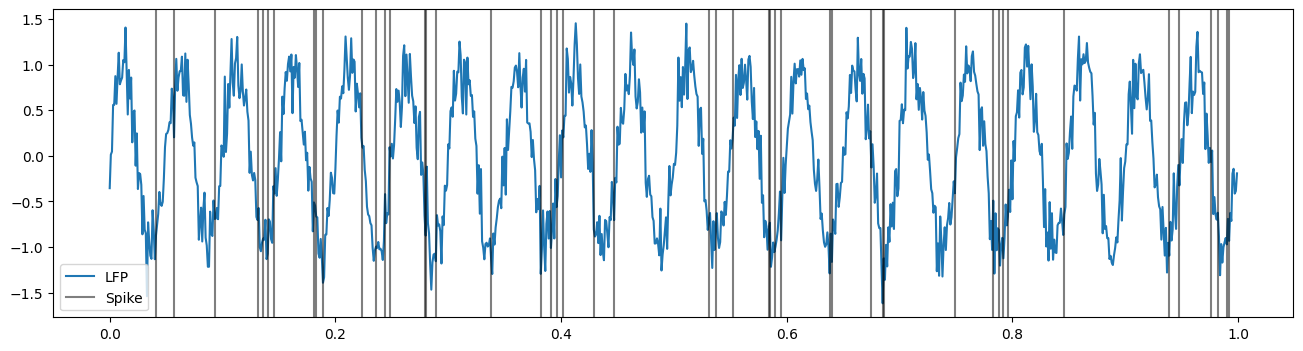

In [ ]:
## Simulated LFP single-band LFP

times = np.arange(0, 1, 1/LFP_SAMPLING_RATE)
freq = 20
synth_lfp = np.sin(2 * np.pi * times[:] * freq)
noise = np.random.normal(0, .2, size=times.shape)
synth_lfp += noise


plt.figure(figsize=(16, 4))
plt.plot(times, synth_lfp, label='LFP')
#Simulate neuron
spike_times = []
lfp_min0 = synth_lfp - np.min(synth_lfp)+.001
for i in range(0,len(times)):
    probability = (2 - lfp_min0[i])/10
    if probability > 0:
        sample = np.random.choice([0,1],p=[1-probability, probability])
        if sample==1:
            spike_times.append(times[i])
for idx, spike in enumerate(spike_times):
    if idx == 0:
        plt.axvline(spike, color='black', alpha=.5, label='Spike')
    else:
        plt.axvline(spike, color='black', alpha=.5)
plt.legend()

synth LFP: 1000 samples @ 1000 Hz, components at [2.5, 6.0, 10.5, 21.5, 43.0] Hz | 76 spikes


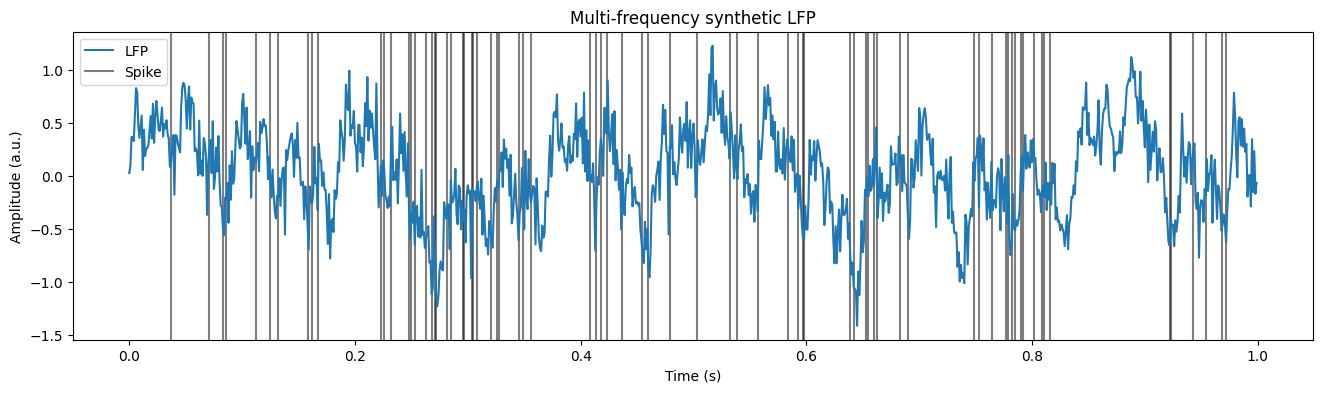

In [ ]:
## Simulated multi-frequency LFP: one oscillation per band of interest

freq_band = {
    "delta (1-4 Hz)": [1, 4],
    "low theta (4-8 Hz)": [4, 8],
    "high theta (8-13 Hz)": [8, 13],
    "beta (13-30 Hz)": [13, 30],
    "low gamma (30-56 Hz)": [30, 56],
}

RNG_SEED = 0
rng = np.random.default_rng(RNG_SEED)

## One component per band, placed at the band centre (Hz, NOT a period) so it passes that
## band's filter and is attenuated by every other band's.
band_names = list(freq_band)
synth_band_freqs = np.array([(low + high) / 2 for low, high in freq_band.values()])

times = np.arange(0, 1, 1 / LFP_SAMPLING_RATE)

## (n_bands, n_samples): row i is the clean ground-truth component for band_names[i].
synth_band_waves = np.sin(2 * np.pi * np.outer(synth_band_freqs, times))
multif_synth_lfp = synth_band_waves.sum(axis=0)
## Rescale the composite back to a +/-1 swing so the spike-probability rule below stays
## calibrated; summing 5 unit sines otherwise drives (2 - lfp_min0)/10 negative everywhere.
multif_synth_lfp /= np.ptp(multif_synth_lfp) / 2
multif_synth_lfp += rng.normal(0, .2, size=times.shape)

## Simulate neuron: spike probability is highest at troughs of the composite LFP.
## Kept under its own name -- rebinding `spike_times` here would silently hand the
## single-frequency cells below this one the multi-frequency spike train.
lfp_min0 = multif_synth_lfp - np.min(multif_synth_lfp) + .001
spike_probability = np.clip((2 - lfp_min0) / 10, 0, 1)
multif_spike_times = times[rng.random(times.size) < spike_probability]

print(f"synth LFP: {multif_synth_lfp.shape[0]} samples @ {LFP_SAMPLING_RATE} Hz, "
      f"components at {np.round(synth_band_freqs, 2).tolist()} Hz | "
      f"{multif_spike_times.size} spikes")

plt.figure(figsize=(16, 4))
plt.plot(times, multif_synth_lfp, label='LFP', zorder=3)
for idx, spike in enumerate(multif_spike_times):
    plt.axvline(spike, color='black', alpha=.5, label='Spike' if idx == 0 else None)
plt.legend()
plt.title(f"Multi-frequency synthetic LFP")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (a.u.)")
plt.show()

In [ ]:
## Real LFP recording object, loaded from .rec object.
## Replace below function inputs of real LFP data's variables for actual analysis.

import sys

LFP_UTILS_DIR = PROJECT_DIR / "utilities/lfp"
TRODES_UTILS_DIR = PROJECT_DIR / "EPhys_data/lfp/trodes"
LFP_COLLECTION_DIR = PROJECT_DIR / "EPhys_data/recordings_rce_both_rewarded"  
LFP_REC_NAME = "20240327_153306_comp_both_subj_3-1_t1b1_merged.rec"


try:
    for module_dir in (LFP_UTILS_DIR, TRODES_UTILS_DIR):
        if str(module_dir) not in sys.path:
            sys.path.insert(0, str(module_dir))
    import LFP_collection

    ## load_rec_from_h5 re-runs the multitaper on rms_traces whenever power is saved, so one recording
    ## is loaded here. Whole collection (as in the reference; 18x the time and memory for rce_both_rewarded):
    ## lfp_collection = LFP_collection.LFPCollection.load_collection(json_path=LFP_COLLECTION_DIR / "lfp_collection.json")
    lfp_recording = LFP_collection.LFPRecording.load_rec_from_h5(
        h5_path=LFP_COLLECTION_DIR / "recordings" / f"{LFP_REC_NAME}.h5"
    )


    print(f"{lfp_recording.name} | subject {lfp_recording.subject} | {lfp_recording.rec_length:.1f} min @ "
        f"{lfp_recording.resample_rate} Hz | traces {lfp_recording.traces.shape}")
    print(f"regions: {dict(lfp_recording.brain_region_dict)}")
    print(f"events: { {key: np.shape(value) for key, value in (lfp_recording.event_dict or {}).items()} }")
except Exception as e:
    print(f"Error loading LFP recording: {e}")
    print("Ensure the LFP recording .rec and .h5 files exist and the paths are correct.")

20240327_153306_comp_both_subj_3-1_t1b1_merged.rec | subject subj_3-1 | 54.4 min @ 1000 Hz | traces (3262503, 5)
regions: {'BLA': 1, 'LH': 2, 'MD': 3, 'mPFC': 4, 'vHPC': 0}
events: {'tone': (43, 2)}


LFP phase: (1000,) samples, band [12, 32] Hz, Butterworth order 4


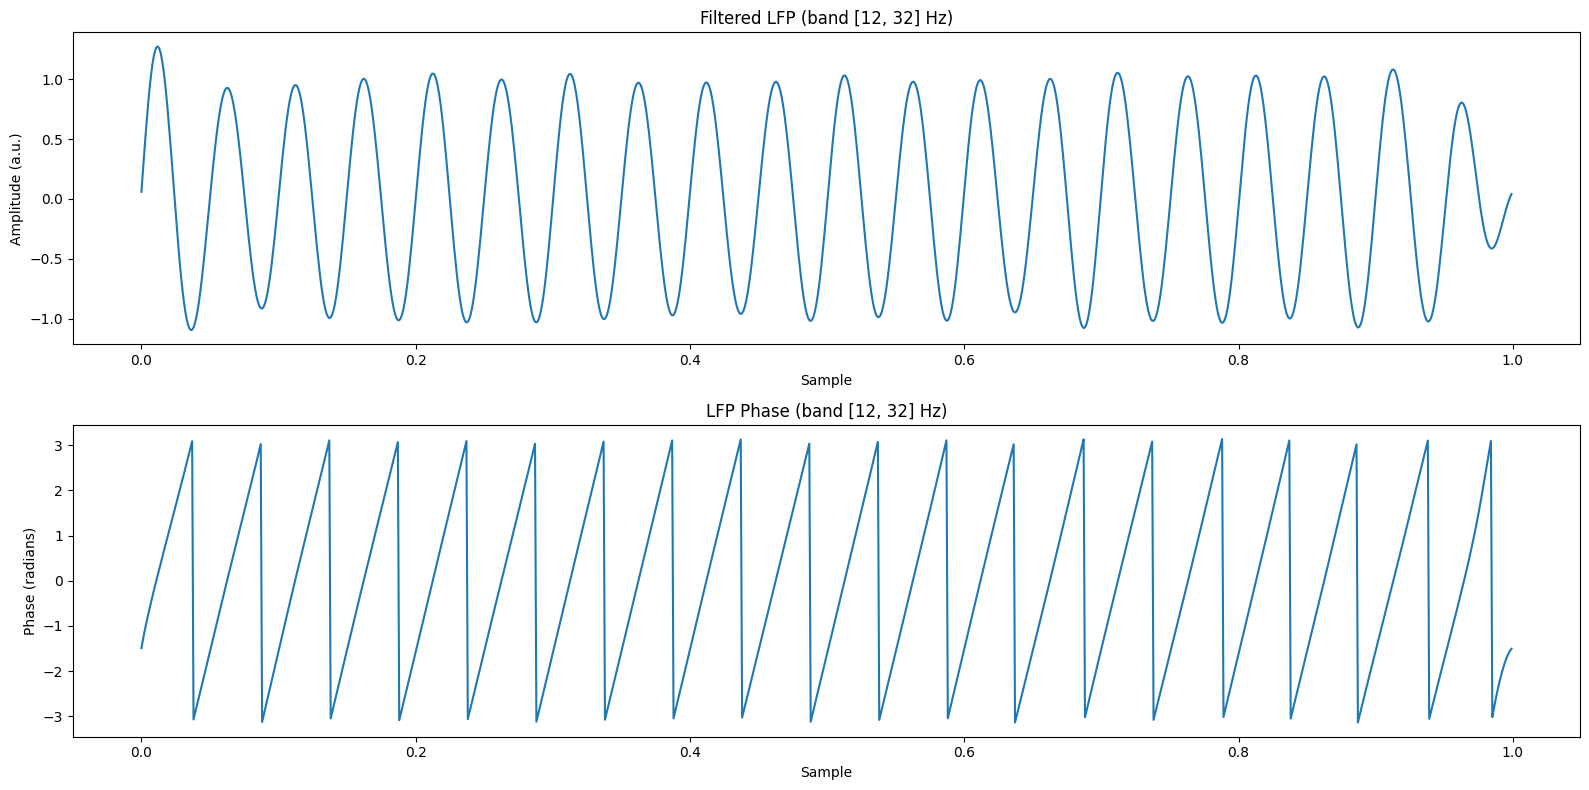

LFP phase: (1000,) samples, band [1, 4] Hz, Butterworth order 4
LFP phase: (1000,) samples, band [4, 8] Hz, Butterworth order 4
LFP phase: (1000,) samples, band [8, 13] Hz, Butterworth order 4
LFP phase: (1000,) samples, band [13, 30] Hz, Butterworth order 4
LFP phase: (1000,) samples, band [30, 56] Hz, Butterworth order 4


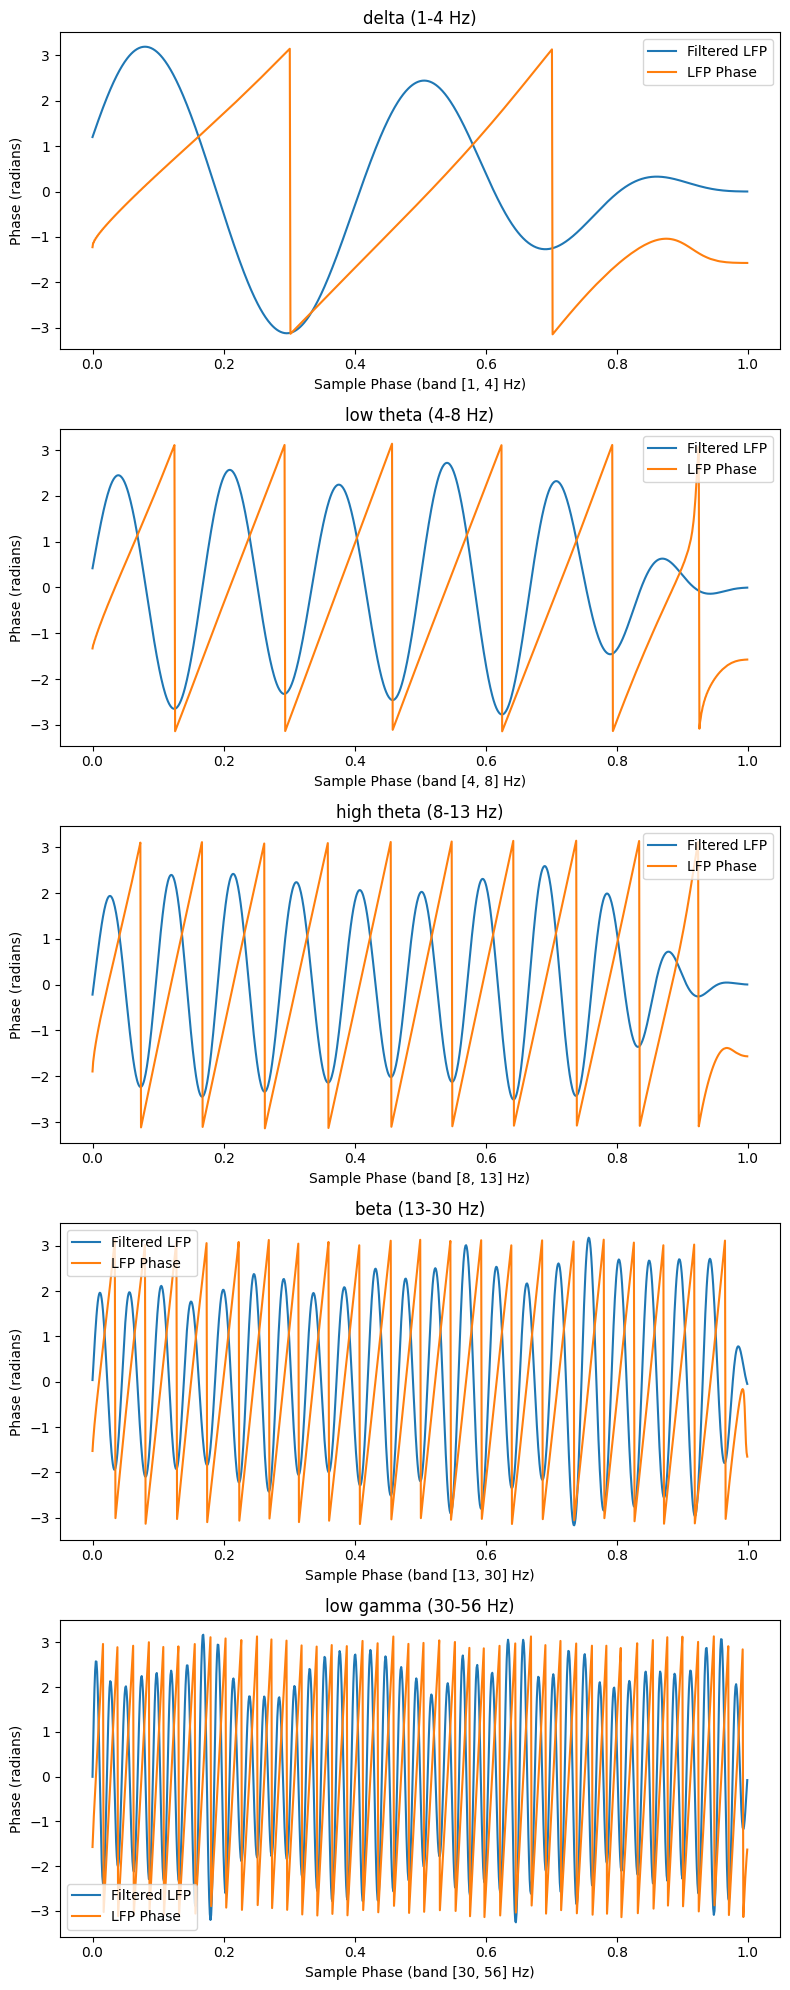

In [51]:
## LFP must be filtered to frequency bin of interest, then hilbert transform is applied to get the instantaneous phase of the LFP.

# this can be applied to normal or multi-frequency synthetic LFP. Just make a loop for each freq band of interest.
sos = sig.butter(N=IIR_ORDER, Wn=BAND, btype="band", fs=LFP_SAMPLING_RATE, output="sos")
lfp_filtered = sig.sosfiltfilt(sos=sos, x=synth_lfp)
lfp_phase = np.angle(sig.hilbert(x=lfp_filtered))
print(f"LFP phase: {lfp_phase.shape} samples, band {BAND} Hz, Butterworth order {IIR_ORDER}")

fig, ax = plt.subplots(2, 1, figsize=(16, 8))
ax[0].plot(times, lfp_filtered, label='Filtered LFP')
ax[1].plot(times, lfp_phase, label='LFP Phase')
ax[0].set_title(f"Filtered LFP (band {BAND} Hz)")
ax[1].set_title(f"LFP Phase (band {BAND} Hz)")
ax[0].set_xlabel("Sample")
ax[0].set_ylabel("Amplitude (a.u.)")
ax[1].set_xlabel("Sample")
ax[1].set_ylabel("Phase (radians)")
plt.tight_layout()
plt.show()

# Per-band loop. Uses its own loop names -- `BAND`/`lfp_filtered`/`lfp_phase` above are the
# single-band result and must survive this cell for the spike-binning cell that follows.
fig, ax = plt.subplots(len(freq_band), 1, figsize=(8, 4*len(freq_band)))
for band_name, band in freq_band.items():
    sos_band = sig.butter(N=IIR_ORDER, Wn=band, btype="band", fs=LFP_SAMPLING_RATE, output="sos")
    band_filtered = sig.sosfiltfilt(sos=sos_band, x=multif_synth_lfp)
    band_phase = np.angle(sig.hilbert(x=band_filtered))
    print(f"LFP phase: {band_phase.shape} samples, band {band} Hz, Butterworth order {IIR_ORDER}")

    ax_idx = list(freq_band).index(band_name)
    ax[ax_idx].plot(times, 10*band_filtered, label='Filtered LFP') # multiply by 10 for better visibility
    ax[ax_idx].plot(times, band_phase, label='LFP Phase')
    ax[ax_idx].legend()
    ax[ax_idx].set_title(band_name)
    ax[ax_idx].set_xlabel(f"Sample Phase (band {band} Hz)")
    ax[ax_idx].set_ylabel("Phase (radians)")
plt.tight_layout()
plt.show()

spikes: 48 kept, 0 dropped | LFP samples with >1 spike: 0
[0. 6. 6. 4. 7. 1. 2. 0. 1. 0. 0. 0. 0. 0. 3. 1. 5. 5. 7.]


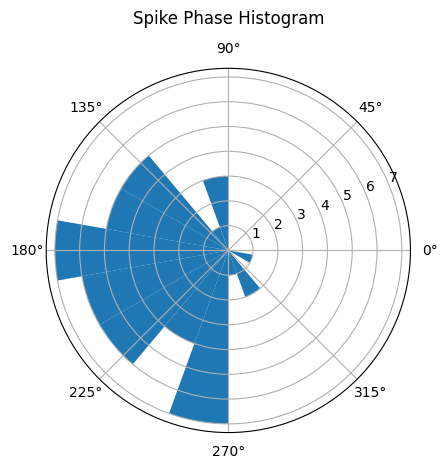

In [52]:
## Spikes must be binned to discrete time bins.
## The bins must have no more than one spike per bin, and preferably similar to the LFP sampling rate, without being too small to avoid empty bins.
## The binning can be done by rounding the spike times to the nearest LFP sample time, or by using a histogram with the same bin edges as the LFP samples.
# spikes outside the LFP time range are DROPPED, not clamped

spike_times_arr = np.asarray(spike_times, dtype=float)
inside = (spike_times_arr >= times[0]) & (spike_times_arr <= times[-1])
spikes_inside = spike_times_arr[inside]
spike_idx = np.searchsorted(a=times, v=spikes_inside)
spike_idx = np.clip(a=spike_idx, a_min=1, a_max=len(times) - 1)
spike_idx = np.where(np.abs(spikes_inside - times[spike_idx - 1]) <= np.abs(spikes_inside - times[spike_idx]),
                     spike_idx - 1, spike_idx)
spike_phases = lfp_phase[spike_idx]

_, spikes_per_bin = np.unique(ar=spike_idx, return_counts=True)
print(f"spikes: {spike_phases.size} kept, {int((~inside).sum())} dropped | "
      f"LFP samples with >1 spike: {int((spikes_per_bin > 1).sum())}")

n_bins = 18
phase_bins = np.linspace(-np.pi, np.pi, n_bins+1)
binned_phases = np.digitize(spike_phases, phase_bins, n_bins+1)
spike_phase_hist = np.zeros(n_bins+1)
for bin in range(0, n_bins + 1):
    spike_phase_hist[bin] = np.sum(binned_phases == bin)
print(spike_phase_hist)

#Plot
ax = plt.subplot(1,1,1, polar=True)
plt.bar(phase_bins, spike_phase_hist, width=phase_bins[1] - phase_bins[0], bottom=0.0)
plt.title("Spike Phase Histogram", y=1.10)
plt.tight_layout()
plt.show()

## PLV & PPC equations

For one unit with $N$ spikes whose LFP phases (radians) are $\theta_1, \dots, \theta_N$:

**PLV**, the mean resultant length ([Lachaux et al., 1999](https://www.sciencedirect.com/science/article/pii/S1053811910000959#bib13)):

$$\text{PLV} = \bar{R} = \left| \frac{1}{N} \sum_{n=1}^{N} e^{i\theta_n} \right| = \frac{1}{N} \sqrt{\left( \sum_{n=1}^{N} \cos\theta_n \right)^2 + \left( \sum_{n=1}^{N} \sin\theta_n \right)^2}$$

$\text{PLV} \in [0, 1]$. It is biased upward at low spike counts: under uniform phases $\mathbb{E}\left[\bar{R}^2\right] = 1/N$, so a unit with few spikes looks locked by chance.

**PPC**, the mean cosine of the phase difference over all spike pairs ([Vinck et al., 2010](https://www.sciencedirect.com/science/article/pii/S1053811910000959)):

$$\text{PPC} = \frac{2}{N(N-1)} \sum_{j=1}^{N-1} \sum_{k=j+1}^{N} \cos\left(\theta_j - \theta_k\right)$$

Because $\left| \sum_{n} e^{i\theta_n} \right|^2 = N + 2 \sum_{j<k} \cos\left(\theta_j - \theta_k\right)$, the pair sum collapses to the $O(N)$ form that `ppc()` computes:

$$\text{PPC} = \frac{\left| \sum_{n=1}^{N} e^{i\theta_n} \right|^2 - N}{N(N-1)} = \frac{N \, \text{PLV}^2 - 1}{N - 1}$$

$\text{PPC} \in \left[ -\tfrac{1}{N-1}, 1 \right]$ with $\mathbb{E}[\text{PPC}] = 0$ under uniform phases. It estimates the *squared* population resultant length $\rho^2$, so compare $\sqrt{\text{PPC}}$, not PPC, against PLV.

In [53]:
## functions of interest

def spike_sample_idx(lfp_times, spikes):
    """Nearest-in-time LFP sample index per spike; out-of-range spikes are DROPPED, not clamped.
    Index-returning counterpart of nearest_phase()."""
    spikes = np.asarray(spikes, dtype=float)
    inside = (spikes >= lfp_times[0]) & (spikes <= lfp_times[-1])
    n_dropped = int((~inside).sum())
    idx = np.searchsorted(lfp_times, spikes[inside])
    idx = np.clip(idx, 1, len(lfp_times) - 1)
    idx = np.where(np.abs(spikes[inside] - lfp_times[idx - 1]) <= np.abs(spikes[inside] - lfp_times[idx]),
                   idx - 1, idx)
    return idx, n_dropped


def spike_count_column(lfp_times, spikes):
    """Per-sample spike counts. Counts rather than bools, so bins with >1 spike keep their weight."""
    idx, n_dropped = spike_sample_idx(lfp_times, spikes)
    return np.bincount(idx, minlength=len(lfp_times)), n_dropped


def spike_phases_from(df, phase_col, count_col="spike_count"):
    """Spike phases out of a binned dataframe; a bin with n spikes contributes its phase n times."""
    return np.repeat(df[phase_col].to_numpy(), df[count_col].to_numpy())

def phase_band(trace, band, sampling_rate=LFP_SAMPLING_RATE, order=IIR_ORDER):
    """Zero-phase Butterworth bandpass (SOS) + Hilbert -> instantaneous phase."""
    sos = sig.butter(order, band, btype="band", fs=sampling_rate, output="sos")
    return np.angle(sig.hilbert(sig.sosfiltfilt(sos, trace)))


def nearest_phase(phase, lfp_times, spikes):
    """Nearest-in-time LFP phase per spike; out-of-range spikes are DROPPED, not clamped."""
    inside = (spikes >= lfp_times[0]) & (spikes <= lfp_times[-1])
    n_dropped = int((~inside).sum())
    spikes = spikes[inside]
    idx = np.searchsorted(lfp_times, spikes)
    idx = np.clip(idx, 1, len(lfp_times) - 1)
    idx = np.where(np.abs(spikes - lfp_times[idx - 1]) <= np.abs(spikes - lfp_times[idx]),
                   idx - 1, idx)
    return phase[idx], n_dropped


def plv(phases):
    """Spike-field phase-locking value, |mean(exp(i*phases))| over spike phases (adapted from Lachaux 1999); biased by spike count."""
    phases = np.asarray(phases, float)
    return np.hypot(np.cos(phases).mean(), np.sin(phases).mean()) if phases.size else np.nan


def ppc(phases):
    """
    Pairwise phase consistency (Vinck 2010), unbiased by spike count
    WARNING: longer to compute for large numbers of spikes, so highly recommended to save output
    """
    phases = np.asarray(phases, float)
    n_spikes = phases.size
    if n_spikes < 2:
        return np.nan
    resultant = np.exp(1j * phases).sum()
    return (np.abs(resultant) ** 2 - n_spikes) / (n_spikes * (n_spikes - 1))


def rayleigh_test(phases):
    """Rayleigh test of circular uniformity -> (Z, p). p is Zar's approximation (Biostatistical Analysis, p. 617),
    as in CircStat circ_rtest (Berens 2009). p underflows to 0 for strong locking with many spikes."""
    phases = np.asarray(phases, float)
    n_spikes = phases.size
    resultant_length = n_spikes * plv(phases=phases)
    rayleigh_z = resultant_length ** 2 / n_spikes
    p_value = np.exp(np.sqrt(1 + 4 * n_spikes + 4 * (n_spikes ** 2 - resultant_length ** 2)) - (1 + 2 * n_spikes))
    return rayleigh_z, p_value


## LFP + spikes as dataframes

One row per LFP sample. Spikes are folded in as a per-sample `spike_count` (an integer, not a
bool, so a bin holding more than one spike is not lost), which makes the spike phases for any
band a one-liner: `np.repeat(df["beta_phase"], df["spike_count"])`.

- `single_lfp_df` -- sample 1, the single 20 Hz rhythm, filtered at `BAND`.
- `multif_lfp_df` -- sample 2, the composite, with ground-truth / filtered / phase columns per band.

In [54]:
## Sample 1 (single-frequency) as a dataframe.


sos_single = sig.butter(N=IIR_ORDER, Wn=BAND, btype="band", fs=LFP_SAMPLING_RATE, output="sos")
single_counts, single_dropped = spike_count_column(times, spike_times)

single_lfp_df = pd.DataFrame({
    "time": times,
    "lfp": synth_lfp,
    "spike_count": single_counts,
    "lfp_filtered": sig.sosfiltfilt(sos=sos_single, x=synth_lfp),
    "lfp_phase": phase_band(synth_lfp, BAND),
})
single_lfp_df["spike"] = single_lfp_df["spike_count"] > 0

print(f"single_lfp_df: {single_lfp_df.shape[0]} samples x {single_lfp_df.shape[1]} cols | "
      f"{int(single_counts.sum())} spikes ({single_dropped} dropped, "
      f"{int((single_counts > 1).sum())} bins with >1)")
single_lfp_df.head()

single_lfp_df: 1000 samples x 6 cols | 48 spikes (0 dropped, 0 bins with >1)


,time,lfp,spike_count,lfp_filtered,lfp_phase,spike
0,0.000,-0.355041,0,0.059025,-1.491704,False
1,0.001,0.012173,0,0.217423,-1.320901,False
2,0.002,0.045812,0,0.374341,-1.159136,False
3,0.003,0.556964,0,0.526687,-1.016208,False
4,0.004,0.558387,0,0.671450,-0.872033,False


In [55]:
## Sample 2 (multi-frequency) as a dataframe: the composite LFP plus, for each band, the
## ground-truth component, the bandpassed trace, and its Hilbert phase. Columns are named by
## band slug, e.g. "beta_filtered" / "beta_phase".

band_slug = {name: name.split(" (")[0].replace(" ", "_") for name in band_names}
multif_counts, multif_dropped = spike_count_column(times, multif_spike_times)

multif_lfp_df = pd.DataFrame({
    "time": times,
    "lfp": multif_synth_lfp,
    "spike_count": multif_counts,
})
multif_lfp_df["spike"] = multif_lfp_df["spike_count"] > 0

for name, truth in zip(band_names, synth_band_waves):
    slug, band = band_slug[name], freq_band[name]
    sos_band = sig.butter(N=IIR_ORDER, Wn=band, btype="band", fs=LFP_SAMPLING_RATE, output="sos")
    multif_lfp_df[f"{slug}_truth"] = truth
    multif_lfp_df[f"{slug}_filtered"] = sig.sosfiltfilt(sos=sos_band, x=multif_synth_lfp)
    multif_lfp_df[f"{slug}_phase"] = phase_band(multif_synth_lfp, band)

print(f"multif_lfp_df: {multif_lfp_df.shape[0]} samples x {multif_lfp_df.shape[1]} cols | "
      f"{int(multif_counts.sum())} spikes ({multif_dropped} dropped, "
      f"{int((multif_counts > 1).sum())} bins with >1)")

## Sanity check: each band's filter should recover its own component and little else.
edge = len(times) // 10  # trim filter edge transients before correlating
for name in band_names:
    slug = band_slug[name]
    r = multif_lfp_df[f"{slug}_filtered"][edge:-edge].corr(multif_lfp_df[f"{slug}_truth"][edge:-edge])
    print(f"  {name:22s} corr(filtered, ground truth) = {r:+.3f}")
multif_lfp_df.head()

multif_lfp_df: 1000 samples x 19 cols | 76 spikes (0 dropped, 0 bins with >1)
  delta (1-4 Hz)         corr(filtered, ground truth) = +0.902
  low theta (4-8 Hz)     corr(filtered, ground truth) = +0.961
  high theta (8-13 Hz)   corr(filtered, ground truth) = +0.974
  beta (13-30 Hz)        corr(filtered, ground truth) = +0.979
  low gamma (30-56 Hz)   corr(filtered, ground truth) = +0.971


,time,lfp,spike_count,spike,delta_truth,delta_filtered,delta_phase,low_theta_truth,low_theta_filtered,low_theta_phase,high_theta_truth,high_theta_filtered,high_theta_phase,beta_truth,beta_filtered,beta_phase,low_gamma_truth,low_gamma_filtered,low_gamma_phase
0,0.000,0.025146,0,False,0.000000,0.119819,-1.224020,0.000000,0.041940,-1.329987,0.000000,-0.021783,-1.895634,0.000000,0.003703,-1.528276,0.000000,-0.000434,-1.573438
1,0.001,0.094870,0,False,0.015707,0.124019,-1.127447,0.037690,0.050002,-1.255955,0.065926,-0.010619,-1.685787,0.134678,0.029413,-1.298568,0.266902,0.072502,-1.216598
2,0.002,0.365507,0,False,0.031411,0.128203,-1.119121,0.075327,0.058048,-1.218448,0.131564,0.000718,-1.563456,0.266902,0.054945,-1.110003,0.514440,0.140081,-0.884658
3,0.003,0.364550,0,False,0.047106,0.132370,-1.070111,0.112856,0.066065,-1.163347,0.196631,0.012177,-1.458506,0.394263,0.079764,-0.947206,0.724653,0.196456,-0.603436
4,0.004,0.328430,0,False,0.062791,0.136517,-1.060713,0.150226,0.074043,-1.125986,0.260842,0.023707,-1.359820,0.514440,0.103340,-0.793841,0.882291,0.236745,-0.306476


## Spike-field coupling per band: PLV, PPC

`plv` returns the mean resultant length |mean(exp(i*phase))|

 `ppc` is the bias-corrected estimator (PPC ~ (n*PLV^2 - 1)/(n - 1))

In [56]:
## One row per band: spike count, MVL + its Rayleigh p, PLV, PPC, and the preferred phase.

rows = []
for name in band_names:
    slug = band_slug[name]
    phases = spike_phases_from(multif_lfp_df, f"{slug}_phase")
    rows.append({
        "band": name,
        "band_slug": slug,
        "centre_hz": sum(freq_band[name]) / 2,
        "n_spikes": phases.size,
        "rayleigh_p": rayleigh_test(phases=phases)[1],
        "PLV": plv(phases),
        "PPC": ppc(phases),
        "mean_phase": np.angle(np.exp(1j * phases).mean()),
    })

multif_metrics_df = pd.DataFrame(rows)
multif_metrics_df

,band,band_slug,centre_hz,n_spikes,rayleigh_p,PLV,PPC,mean_phase
0,delta (1-4 Hz),delta,2.5,76,0.083471,0.180617,0.019724,-2.653267
1,low theta (4-8 Hz),low_theta,6.0,76,0.000531,0.312096,0.085369,3.014168
2,high theta (8-13 Hz),high_theta,10.5,76,0.950413,0.025951,-0.012651,-0.646815
3,beta (13-30 Hz),beta,21.5,76,0.031976,0.212332,0.032352,-3.105194
4,low gamma (30-56 Hz),low_gamma,43.0,76,0.051178,0.197449,0.026173,-3.098697


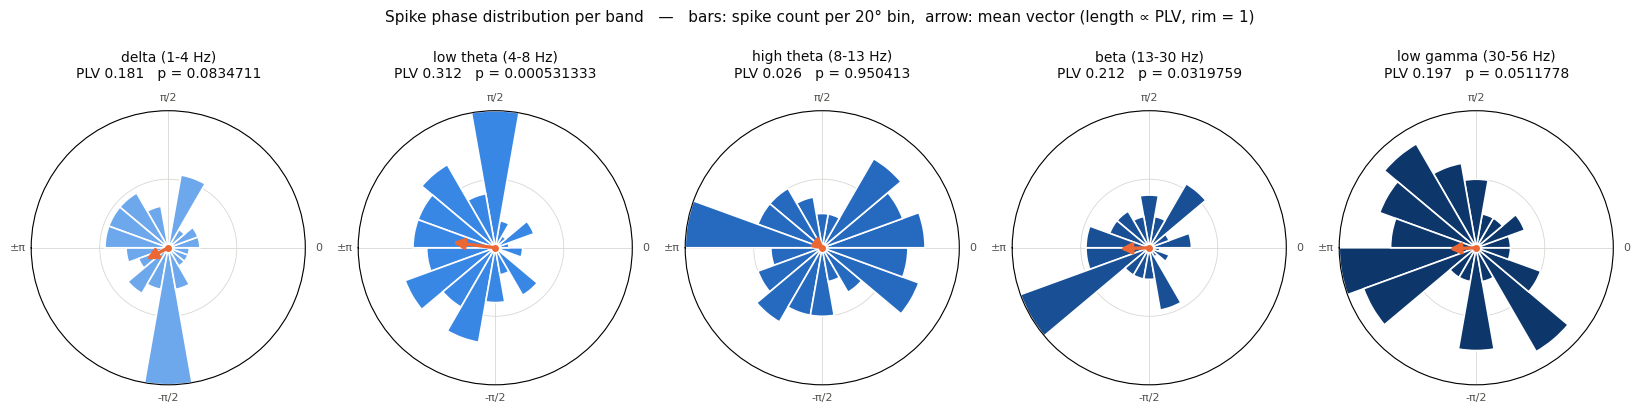

In [57]:
## PLV, drawn: the spike-phase distribution per band with its mean resultant vector.
## Arrow direction = preferred phase; arrow length is proportional to PLV, with the rim = 1.

## Ordinal blue ramp -- darker with increasing band frequency.
BAND_RAMP = ["#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
ARROW_COLOR, INK, INK_MUTED, SURFACE = "#eb6834", "#0b0b0b", "#52514e", "#ffffff"

phase_bin_edges = np.linspace(-np.pi, np.pi, 19)  # 20-degree bins
fig, axes = plt.subplots(1, len(band_names), figsize=(3.3 * len(band_names), 4.2),
                         subplot_kw={"projection": "polar"})

for ax, (_, row), color in zip(axes, multif_metrics_df.iterrows(), BAND_RAMP):
    phases = spike_phases_from(multif_lfp_df, f"{row.band_slug}_phase")
    counts, edges = np.histogram(phases, bins=phase_bin_edges)
    ax.bar(edges[:-1], counts, width=np.diff(edges), align="edge",
           color=color, edgecolor=SURFACE, linewidth=1.2, zorder=2)

    ax.annotate("", xy=(row.mean_phase, row.PLV * counts.max()), xytext=(0, 0),
                arrowprops=dict(arrowstyle="-|>", color=ARROW_COLOR, lw=2.4,
                                mutation_scale=16, shrinkA=0, shrinkB=0), zorder=4)
    ax.plot(0, 0, marker="o", markersize=4, color=ARROW_COLOR, zorder=4)

    ## set_thetalim first -- set_xticks alone would widen the theta range past one turn.
    ax.set_thetalim(-np.pi, np.pi)
    ax.set_xticks([-np.pi, -np.pi / 2, 0, np.pi / 2])
    ax.set_xticklabels(["\u00b1\u03c0", "-\u03c0/2", "0", "\u03c0/2"], fontsize=8, color=INK_MUTED)
    ax.set_rmax(counts.max())
    ax.set_yticks([counts.max() / 2, counts.max()])
    ax.set_yticklabels([])
    ax.grid(color="#d8d7d3", linewidth=0.6)
    ax.tick_params(axis="x", pad=-1)
    ax.set_title(f"{row.band}\nPLV {row.PLV:.3f}   p = {row.rayleigh_p:g}",
                 fontsize=10, color=INK, pad=24)

fig.suptitle("Spike phase distribution per band   \u2014   bars: spike count per 20\u00b0 bin,  "
             "arrow: mean vector (length \u221d PLV, rim = 1)", fontsize=11, color=INK, y=1.02)
plt.tight_layout()
plt.show()

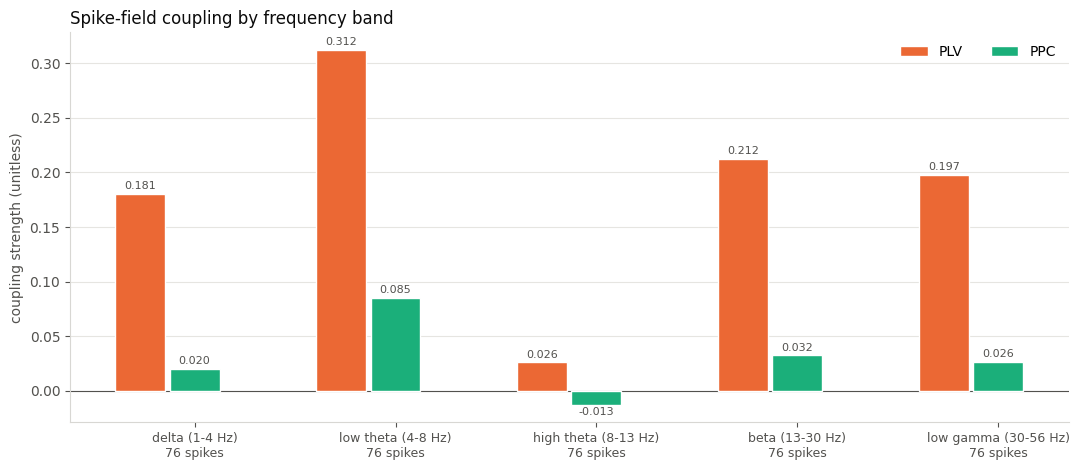

In [58]:
## PLV / PPC side by side per band.
## the PLV -> PPC drop is the spike-count bias being removed.

METRIC_COLORS = {"PLV": "#eb6834", "PPC": "#1baf7a"}
INK, INK_MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"

x = np.arange(len(multif_metrics_df))
width = 0.27
fig, ax = plt.subplots(figsize=(11, 4.8))

for i, (metric, color) in enumerate(METRIC_COLORS.items()):
    ## White edge keeps a visible gap between adjacent bars within a group.
    bars = ax.bar(x + (i - 1) * width, multif_metrics_df[metric], width * 0.92,
                  label=metric, color=color, edgecolor="#ffffff", linewidth=1.0, zorder=2)
    ax.bar_label(bars, fmt="%.3f", fontsize=8, padding=2, color=INK_MUTED)

ax.axhline(0, color=INK_MUTED, linewidth=0.8, zorder=1)
ax.set_xticks(x)
ax.set_xticklabels([f"{row.band}\n{int(row.n_spikes)} spikes"
                    for _, row in multif_metrics_df.iterrows()], fontsize=9, color=INK)
ax.set_ylabel("coupling strength (unitless)", color=INK_MUTED)
ax.set_title("Spike-field coupling by frequency band", fontsize=12, color=INK, loc="left")
ax.legend(frameon=False, ncols=3, loc="upper right")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color("#d8d7d3")
ax.tick_params(colors=INK_MUTED)
plt.tight_layout()
plt.show()

## Rayleigh test: significance of synchrony

PLV and PPC measure *how strongly* a unit locks; the Rayleigh test asks whether that locking could be chance.  
- $H_0$: spike phases are uniform on the circle.  
- $H_1$: they concentrate around one preferred phase (unimodal).  

$$R = N \bar{R} = N \, \text{PLV}, \qquad Z = \frac{R^2}{N} = N \, \text{PLV}^2$$

p is Zar's approximation (*Biostatistical Analysis*, p. 617), the same one CircStat's [`circ_rtest`](https://github.com/circstat/circstat-matlab/blob/master/circ_rtest.m) uses ([Berens 2009](https://www.jstatsoft.org/article/view/v031i10)):

$$p \approx \exp\left( \sqrt{1 + 4N + 4\left(N^2 - R^2\right)} - (1 + 2N) \right)$$

For large $N$ this tends to $p \approx e^{-Z}$.


**Synthetic data used below**
1. The demo spike trains above: the single 20 Hz sample and each band of the multi-frequency sample.
2. Simulated units whose phases are drawn from a von Mises distribution $\text{VM}(\mu = 0, \kappa)$ ([NumPy `vonmises`](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.vonmises.html)), with population resultant length $\rho = I_1(\kappa) / I_0(\kappa)$. At $\kappa = 0$ (uniform) the rejection rate should equal $\alpha$ (calibration); it should rise with $\kappa$ and $N$ (power).

2000 simulated units per point; phases ~ von Mises(mu=0, kappa). kappa=0 (dashed gray) is the uniform null: expected rate 0.05 +/- 0.010 (2 SE). Dotted line = alpha. x-axis log-scaled.
n_spikes                  10     25     50     100    250    500
concentration                                                   
kappa=0 (rho=0.000)     0.047  0.054  0.046  0.054  0.052  0.056
kappa=0.1 (rho=0.050)   0.051  0.058  0.068  0.098  0.148  0.280
kappa=0.25 (rho=0.124)  0.083  0.108  0.190  0.335  0.706  0.948
kappa=0.5 (rho=0.242)   0.140  0.321  0.590  0.888  0.999  1.000
kappa=1.0 (rho=0.446)   0.432  0.869  0.994  1.000  1.000  1.000


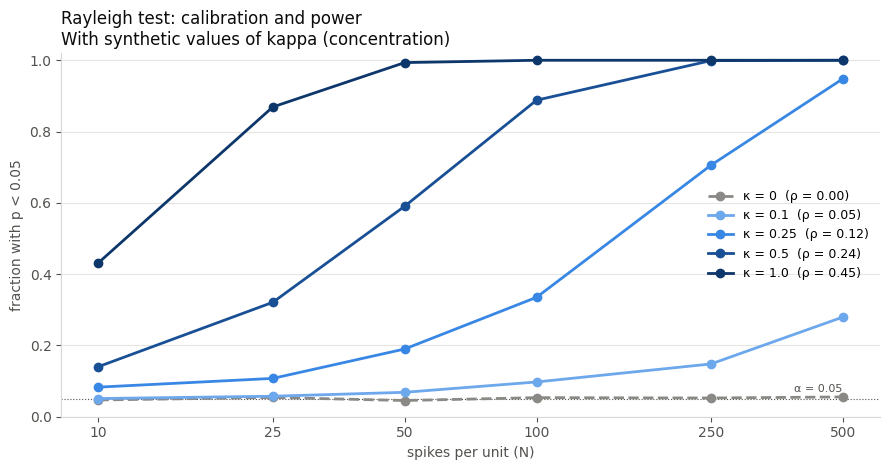

In [59]:
## Calibration and power on von Mises phases: fraction of RAYLEIGH_N_SIMS simulated units with
## p < RAYLEIGH_ALPHA, per (kappa, spike count). kappa = 0 is the uniform null, so its rate should sit at alpha.

## Simulation parameters for the von Mises sweep (used only in this cell)
RAYLEIGH_N_SIMS = 2000
RAYLEIGH_SEED = 1

RAYLEIGH_KAPPAS = [0, 0.1, 0.25, 0.5, 1.0] # concentration parameters of von Mises distributions for Rayleigh demonstration
RAYLEIGH_SPIKE_COUNTS = [10, 25, 50, 100, 250, 500]  # synthetic spike counts for Rayleigh demonstration
RAYLEIGH_KAPPA_COLORS = ["#8a8985", "#6da7ec", "#3987e5", "#184f95", "#0d366b"] ## Neutral gray for the null, then a blue ramp darkening with kappa.

rayleigh_rng = np.random.default_rng(seed=RAYLEIGH_SEED)

rejection_rate = np.zeros(shape=(len(RAYLEIGH_KAPPAS), len(RAYLEIGH_SPIKE_COUNTS)))
for kappa_idx, kappa in enumerate(RAYLEIGH_KAPPAS):
    for count_idx, n_spikes in enumerate(RAYLEIGH_SPIKE_COUNTS):
        sim_phases = rayleigh_rng.vonmises(mu=0, kappa=kappa, size=(RAYLEIGH_N_SIMS, n_spikes))
        sim_p = np.array([rayleigh_test(phases=unit_phases)[1] for unit_phases in sim_phases])
        rejection_rate[kappa_idx, count_idx] = np.mean(sim_p < RAYLEIGH_ALPHA)

## Population resultant length of VM(0, kappa); 0 at kappa = 0.
population_rho = i1(RAYLEIGH_KAPPAS) / i0(RAYLEIGH_KAPPAS)

rejection_df = pd.DataFrame(
    data=rejection_rate,
    index=pd.Index(data=[f"kappa={kappa} (rho={rho:.3f})" for kappa, rho in zip(RAYLEIGH_KAPPAS, population_rho)],
                   name="concentration"),
    columns=pd.Index(data=RAYLEIGH_SPIKE_COUNTS, name="n_spikes"),
)
null_se = np.sqrt(RAYLEIGH_ALPHA * (1 - RAYLEIGH_ALPHA) / RAYLEIGH_N_SIMS)
print(f"{RAYLEIGH_N_SIMS} simulated units per point; phases ~ von Mises(mu=0, kappa). "
      f"kappa=0 (dashed gray) is the uniform null: expected rate {RAYLEIGH_ALPHA} +/- {2 * null_se:.3f} (2 SE). "
      f"Dotted line = alpha. x-axis log-scaled.")
print(rejection_df.round(decimals=3))

fig, power_axis = plt.subplots(figsize=(9, 4.8))
power_axis.axhline(y=RAYLEIGH_ALPHA, color=INK_MUTED, linewidth=0.8, linestyle=":", zorder=1)
power_axis.text(x=RAYLEIGH_SPIKE_COUNTS[-1], y=RAYLEIGH_ALPHA + 0.02, s=f"α = {RAYLEIGH_ALPHA}",
                ha="right", fontsize=8, color=INK_MUTED)
for kappa, rho, rates, color in zip(RAYLEIGH_KAPPAS, population_rho, rejection_rate, RAYLEIGH_KAPPA_COLORS):
    power_axis.plot(RAYLEIGH_SPIKE_COUNTS, rates, color=color, linewidth=2, marker="o", markersize=6,
                    linestyle="--" if kappa == 0 else "-", zorder=2,
                    label=f"κ = {kappa}  (ρ = {rho:.2f})")

power_axis.set_xscale(value="log")
power_axis.set_xticks(ticks=RAYLEIGH_SPIKE_COUNTS, labels=[str(count) for count in RAYLEIGH_SPIKE_COUNTS])
power_axis.minorticks_off()
power_axis.set_ylim(bottom=0, top=1.02)
power_axis.set_xlabel(xlabel="spikes per unit (N)", color=INK_MUTED)
power_axis.set_ylabel(ylabel=f"fraction with p < {RAYLEIGH_ALPHA}", color=INK_MUTED)
power_axis.set_title(label="Rayleigh test: calibration and power\nWith synthetic values of kappa (concentration)", fontsize=12, color=INK, loc="left")
power_axis.legend(frameon=False, loc="center right", fontsize=9)
power_axis.grid(axis="y", color=GRID, linewidth=0.8)
power_axis.set_axisbelow(b=True)
for side in ("top", "right"):
    power_axis.spines[side].set_visible(False)
for side in ("left", "bottom"):
    power_axis.spines[side].set_color("#d8d7d3")
power_axis.tick_params(colors=INK_MUTED)
plt.tight_layout()
plt.show()

In [60]:
## Rayleigh test on the demo spike trains

rayleigh_inputs = {f"single 20 Hz, band {BAND} Hz": spike_phases_from(df=single_lfp_df, phase_col="lfp_phase")}
rayleigh_inputs.update({name: spike_phases_from(df=multif_lfp_df, phase_col=f"{band_slug[name]}_phase")
                        for name in band_names})

rayleigh_rows = []
for name, phases in rayleigh_inputs.items():
    rayleigh_z, rayleigh_p = rayleigh_test(phases=phases)
    rayleigh_rows.append({
        "sample": name,
        "n_spikes": phases.size,
        "PLV": plv(phases=phases),
        "PPC": ppc(phases=phases),
        "rayleigh_z": rayleigh_z,
        "rayleigh_p": rayleigh_p,
        "significant": rayleigh_p < RAYLEIGH_ALPHA,
    })

rayleigh_df = pd.DataFrame(data=rayleigh_rows)
print(f"significant: rayleigh_p < alpha = {RAYLEIGH_ALPHA}, uncorrected for the {len(band_names)} bands.")
rayleigh_df

significant: rayleigh_p < alpha = 0.05, uncorrected for the 5 bands.


,sample,n_spikes,PLV,PPC,rayleigh_z,rayleigh_p,significant
0,"single 20 Hz, band [12, 32] Hz",48,0.634735,0.390184,19.338662,4.470711e-10,True
1,delta (1-4 Hz),76,0.180617,0.019724,2.479308,8.347108e-02,False
2,low theta (4-8 Hz),76,0.312096,0.085369,7.402709,5.313334e-04,True
3,high theta (8-13 Hz),76,0.025951,-0.012651,0.051184,9.504134e-01,False
4,beta (13-30 Hz),76,0.212332,0.032352,3.426435,3.197586e-02,True
5,low gamma (30-56 Hz),76,0.197449,0.026173,2.962941,5.117782e-02,False
